# 04 · Exploratory Data Analysis (EDA)

Agentris · A26-CS193 · Jauza, Data Science

Eksplorasi ini memakai dua CSV bersih dari Mufid yang berisi **data simulasi Agustus–Oktober 2026**. Tujuannya memahami isi dan cakupan data, melihat sebaran nilai dan hubungan antarvariabel, serta menelusuri angka yang terlihat jauh dari transaksi lain. Hasilnya memberi konteks untuk membaca rekap pada notebook 05.

Satu baris penjualan mewakili satu detail menu. Satu nota bisa memuat beberapa detail. Pada CSV pengeluaran, satu baris mewakili satu pengeluaran. Kedua sumber primer WhatsApp tetap tersimpan terpisah karena tanggal lengkap dan rincian menu untuk rekap belum tersedia.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import seaborn as sns
from IPython.display import display


cwd = Path.cwd()
data_science = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "data-science")
        if (candidate / "datasets" / "processed").is_dir()
    ),
    None,
)
if data_science is None:
    raise FileNotFoundError(
        "Folder datasets/processed tidak ditemukan. Buka kernel dari repositori Agentris."
    )
folder_data = data_science / "datasets" / "processed"

NAMA_BULAN = (
    "Januari", "Februari", "Maret", "April", "Mei", "Juni",
    "Juli", "Agustus", "September", "Oktober", "November", "Desember",
)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.dpi": 135})


def rupiah(nilai):
    return f"Rp{nilai:,.0f}".replace(",", ".")


def nama_bulan(periode):
    return f"{NAMA_BULAN[periode.month - 1]} {periode.year}"


def tanggal_indonesia(tanggal):
    return f"{tanggal.day} {nama_bulan(tanggal)}"

Sel ini menyiapkan lokasi CSV di `datasets/processed`, format tanggal dan rupiah, serta gaya grafik Seaborn. Analisis memakai kolom transaksi yang dibutuhkan untuk memeriksa jumlah unit, nominal, dan tanggal.

## 1. Struktur, kelengkapan, dan cakupan data

Profil membaca tipe data dan menghitung nilai kosong, jumlah nilai berbeda, serta penanda `Tidak tercatat` per kolom. Rentang tanggal dan jumlah tanggal yang memiliki transaksi diperiksa untuk masing-masing sumber. Kode juga memeriksa bahwa satu nota berada pada satu tanggal dan jumlah subtotalnya cocok dengan total nota.

In [2]:
def baca_csv(nama_file, id_baris, kolom_teks, kolom_angka):
    kolom = [id_baris, "tanggal", *kolom_teks, *kolom_angka]
    data = pd.read_csv(folder_data / nama_file, usecols=kolom, dtype="string")
    if data.empty or data.isna().any().any():
        raise ValueError(f"{nama_file} kosong atau memiliki sel wajib yang hilang.")
    if data.apply(lambda kolom: kolom.str.strip().eq("").any()).any():
        raise ValueError(f"{nama_file} memiliki sel wajib yang berisi spasi saja.")
    if data[id_baris].duplicated().any():
        raise ValueError(f"{nama_file} memiliki {id_baris} yang berulang.")
    if not data["tanggal"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all():
        raise ValueError(f"{nama_file} harus memakai tanggal berformat YYYY-MM-DD.")

    data["tanggal"] = pd.to_datetime(data["tanggal"], format="%Y-%m-%d")
    data[kolom_angka] = data[kolom_angka].astype("int64")
    if data[kolom_angka].le(0).any().any():
        raise ValueError(f"Jumlah dan nominal dalam {nama_file} harus positif.")
    return data


penjualan = baca_csv(
    "penjualan_sintetis_clean.csv",
    id_baris="id_detail",
    kolom_teks=["id_transaksi", "jenis_makanan"],
    kolom_angka=["jumlah", "harga_satuan", "subtotal", "total_transaksi"],
)
pengeluaran = baca_csv(
    "pengeluaran_sintetis_clean.csv",
    id_baris="no",
    kolom_teks=["keterangan"],
    kolom_angka=["total"],
)

if not penjualan["subtotal"].eq(penjualan["jumlah"] * penjualan["harga_satuan"]).all():
    raise ValueError("Ada subtotal penjualan yang berbeda dari jumlah × harga satuan.")

per_nota = penjualan.groupby("id_transaksi").agg(
    tanggal=("tanggal", "first"),
    jumlah_tanggal=("tanggal", "nunique"),
    subtotal=("subtotal", "sum"),
    total_nota=("total_transaksi", "first"),
    jumlah_total=("total_transaksi", "nunique"),
)
if not (per_nota["jumlah_tanggal"].eq(1) & per_nota["jumlah_total"].eq(1)).all():
    raise ValueError("Satu ID nota memiliki beberapa tanggal atau total yang berbeda.")
if not per_nota["subtotal"].eq(per_nota["total_nota"]).all():
    raise ValueError("Jumlah subtotal pada satu nota berbeda dari total nota.")

profil = []
for nama, data in (("Penjualan", penjualan), ("Pengeluaran", pengeluaran)):
    profil.append(pd.DataFrame({
        "Sumber": nama,
        "Kolom": data.columns,
        "Tipe": data.dtypes.astype(str).to_numpy(),
        "Kosong": data.isna().sum().to_numpy(),
        "Nilai unik": data.nunique().to_numpy(),
        "Penanda Tidak tercatat": [
            data[kolom].eq("Tidak tercatat").sum() for kolom in data.columns
        ],
    }))
display(pd.concat(profil, ignore_index=True).style.hide(axis="index"))

cakupan = pd.DataFrame([
    {
        "Sumber": nama,
        "Baris": len(data),
        "ID unik": data[id_transaksi].nunique(),
        "Baris identik berulang": int(data.duplicated().sum()),
        "Tanggal dengan catatan": data["tanggal"].nunique(),
        "Awal": tanggal_indonesia(data["tanggal"].min()),
        "Akhir": tanggal_indonesia(data["tanggal"].max()),
    }
    for nama, data, id_transaksi in (
        ("Penjualan", penjualan, "id_transaksi"),
        ("Pengeluaran", pengeluaran, "no"),
    )
])
display(cakupan.style.hide(axis="index"))

Sumber,Kolom,Tipe,Kosong,Nilai unik,Penanda Tidak tercatat
Penjualan,id_transaksi,string,0,1148,0
Penjualan,tanggal,datetime64[ns],0,92,0
Penjualan,jenis_makanan,string,0,23,0
Penjualan,jumlah,int64,0,4,0
Penjualan,harga_satuan,int64,0,12,0
Penjualan,subtotal,int64,0,22,0
Penjualan,id_detail,string,0,2573,0
Penjualan,total_transaksi,int64,0,87,0
Pengeluaran,no,string,0,457,0
Pengeluaran,tanggal,datetime64[ns],0,92,0


Sumber,Baris,ID unik,Baris identik berulang,Tanggal dengan catatan,Awal,Akhir
Penjualan,2573,1148,0,92,1 Agustus 2026,31 Oktober 2026
Pengeluaran,457,457,0,92,1 Agustus 2026,31 Oktober 2026


Terdapat 2.573 detail penjualan dari 1.148 nota dan 457 pengeluaran. Kedua sumber punya catatan pada 92 tanggal, dari 1 Agustus sampai 31 Oktober 2026. Tanggal yang tercakup membantu menentukan periode rekap. Untuk data warung, jumlah tanggal yang tercakup saja belum cukup untuk memastikan semua transaksi sudah dicatat.

Tidak ada sel kosong atau baris identik berulang pada kolom yang dibaca. Namun, empat pengeluaran masih memiliki keterangan `Tidak tercatat`. Nominal empat baris itu tetap masuk perhitungan uang keluar. Jika pengeluaran dikelompokkan menurut jenis belanja, keempatnya perlu tetap terlihat sebagai keterangan yang belum diketahui.

## 2. Distribusi nominal dan jumlah nota

Total penjualan dihitung sekali per nota. Pengeluaran diperiksa per catatan dan frekuensi penjualan dihitung per tanggal. Histogram menunjukkan seberapa sering nilai muncul. Median dan kuartil memberi gambaran tentang nilai tengah dan sebaran separuh data di sekitar tengah.

Untuk menandai nilai di ekor distribusi, batas bawah ditetapkan pada Q1 dikurangi 1,5 × IQR dan batas atas pada Q3 ditambah 1,5 × IQR. IQR adalah selisih Q3 dan Q1. Nilai yang berada di luar batas ditandai untuk ditinjau lebih lanjut. Pada grafik, garis oranye menunjukkan batas yang berada di dalam rentang pengamatan.

Metrik,Jumlah,Minimum,Q1,Median,Q3,Maksimum
Total per nota (Rp),1.148,3.000,14.000,18.000,30.000,94.000
Nominal pengeluaran (Rp),457,1.000,11.000,20.000,33.000,83.000
Nota per hari,92,4,10,12,"14,25",20


Metrik,Batas bawah,Batas atas,Di bawah,Di atas,% nilai ditandai
Total per nota (Rp),-10.000,54.000,0,55,"4,79"
Nominal pengeluaran (Rp),-22.000,66.000,0,11,"2,41"
Nota per hari,"3,62","20,62",0,0,0


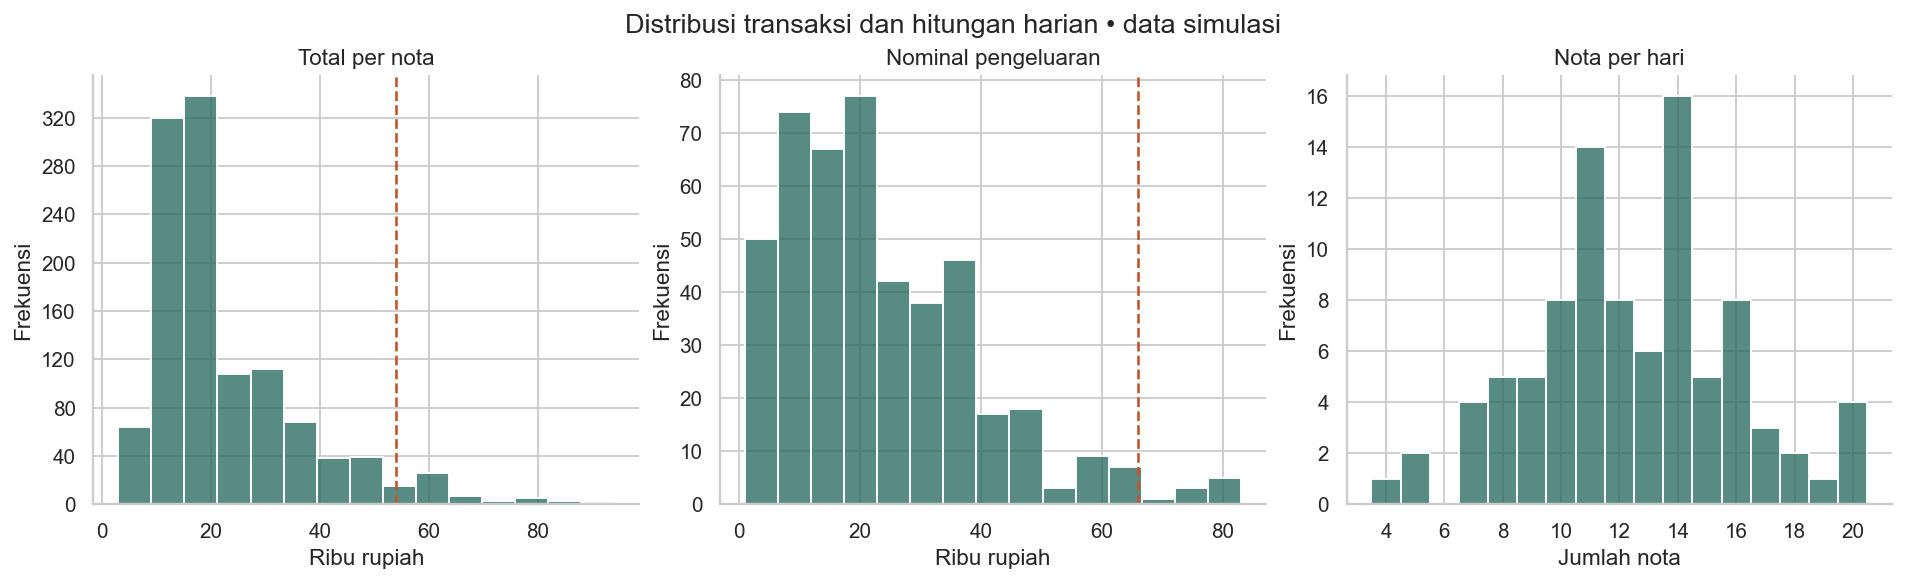

In [3]:
penjualan_harian = per_nota.groupby("tanggal", as_index=False).agg(
    jumlah_nota=("total_nota", "size"),
    pemasukan=("total_nota", "sum"),
)
metrik = {
    "Total per nota (Rp)": per_nota["total_nota"],
    "Nominal pengeluaran (Rp)": pengeluaran["total"],
    "Nota per hari": penjualan_harian["jumlah_nota"],
}
sebaran = []
batas = []
di_luar_batas = {}
for nama, nilai in metrik.items():
    q1, q3 = nilai.quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rendah, tinggi = nilai.lt(bawah), nilai.gt(atas)
    di_luar_batas[nama] = rendah | tinggi
    sebaran.append({
        "Metrik": nama, "Jumlah": len(nilai), "Minimum": nilai.min(), "Q1": q1,
        "Median": nilai.median(), "Q3": q3, "Maksimum": nilai.max(),
    })
    batas.append({
        "Metrik": nama, "Batas bawah": bawah, "Batas atas": atas,
        "Di bawah": rendah.sum(), "Di atas": tinggi.sum(),
        "% nilai ditandai": 100 * di_luar_batas[nama].mean(),
    })

def format_angka(nilai):
    return f"{nilai:,.2f}".rstrip("0").rstrip(".").translate(str.maketrans(",.", ".,"))


display(pd.DataFrame(sebaran).style.format(format_angka, subset=[
    "Jumlah", "Minimum", "Q1", "Median", "Q3", "Maksimum",
]).hide(axis="index"))
display(pd.DataFrame(batas).style.format(format_angka, subset=[
    "Batas bawah", "Batas atas", "Di bawah", "Di atas", "% nilai ditandai",
]).hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained")
for ax, (nama, nilai), ambang in zip(axes, metrik.items(), batas):
    nominal = nama.endswith("(Rp)")
    skala = 1_000 if nominal else 1
    sns.histplot(
        x=nilai / skala, bins=15, discrete=not nominal, color="#206658", ax=ax,
    )
    for batas_iqr in (ambang["Batas bawah"], ambang["Batas atas"]):
        if nilai.min() < batas_iqr < nilai.max():
            ax.axvline(batas_iqr / skala, linestyle="--", color="#BE572E", linewidth=1.4)
    ax.set(
        title=nama.removesuffix(" (Rp)"),
        xlabel="Ribu rupiah" if nominal else "Jumlah nota",
        ylabel="Frekuensi",
    )
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    if not nominal:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    sns.despine(ax=ax)
fig.suptitle("Distribusi transaksi dan hitungan harian • data simulasi")
plt.show()

Median total nota adalah Rp18.000 dan median pengeluaran Rp20.000. Kedua distribusi nominal memanjang ke arah nilai tinggi. Aturan IQR menandai 55 dari 1.148 nota di atas Rp54.000 dan 11 dari 457 pengeluaran di atas Rp66.000. Nilai tertinggi masing-masing Rp94.000 dan Rp83.000.

Jumlah nota harian memiliki median 12 dan berkisar dari 4 sampai 20. Seluruh 92 nilai harian masih berada dalam batas IQR. Ambang nota, pengeluaran, dan hitungan harian dinilai secara terpisah karena ketiganya memakai satuan atau skala yang berbeda.

## 3. Meninjau nilai yang ditandai

Untuk nota, bandingkan jumlah unit pada kelompok yang melewati batas dengan nota lain. Untuk pengeluaran, lihat keterangan yang muncul di antara nilai yang ditandai, lalu hitung ulang batas IQR di dalam kelompok pengeluaran tersebut. Perbandingan ini membantu melihat apakah nominal yang tinggi juga jarang di antara belanja yang sejenis.

In [4]:
unit_per_nota = penjualan.groupby("id_transaksi")["jumlah"].sum()
tinjau_penjualan = per_nota[["total_nota"]].assign(
    unit=unit_per_nota, ditandai=di_luar_batas["Total per nota (Rp)"],
)
ringkasan_nota = tinjau_penjualan.groupby("ditandai").agg(
    Nota=("unit", "size"),
    Median_unit=("unit", "median"),
    Jumlah_nominal=("total_nota", "sum"),
)
ringkasan_nota["% dari pemasukan"] = (
    100 * ringkasan_nota["Jumlah_nominal"] / per_nota["total_nota"].sum()
)
ringkasan_nota.index = ringkasan_nota.index.map({False: "Dalam batas", True: "Di luar batas"})
display(ringkasan_nota.rename_axis("Kelompok nota").rename(columns={
    "Median_unit": "Median unit",
    "Jumlah_nominal": "Jumlah nominal",
}).style.format({
    "Median unit": format_angka, "Jumlah nominal": rupiah, "% dari pemasukan": format_angka,
}))

pengeluaran_ditandai = di_luar_batas["Nominal pengeluaran (Rp)"]
kategori_ditandai = pengeluaran.loc[pengeluaran_ditandai, "keterangan"].unique()
konteks = []
for kategori in sorted(kategori_ditandai):
    satu_kategori = pengeluaran.loc[pengeluaran["keterangan"].eq(kategori), "total"]
    q1, q3 = satu_kategori.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    konteks.append({
        "Keterangan": kategori,
        "Jumlah catatan": len(satu_kategori),
        "Median (Rp)": satu_kategori.median(),
        "Ditandai pada semua pengeluaran": int(pengeluaran_ditandai.loc[satu_kategori.index].sum()),
        "Batas atas dalam kelompok (Rp)": batas_atas,
        "Ditandai dalam kelompok": int((~satu_kategori.between(batas_bawah, batas_atas)).sum()),
    })
if konteks:
    tabel_konteks = pd.DataFrame(konteks)
    display(tabel_konteks.style.format(
        format_angka, subset=["Median (Rp)", "Batas atas dalam kelompok (Rp)"],
    ).hide(axis="index"))
else:
    print("Tidak ada nominal pengeluaran di luar batas IQR.")

,Nota,Median unit,Jumlah nominal,% dari pemasukan
Kelompok nota,,,,
Dalam batas,1093,2,Rp22.891.000,"86,41"
Di luar batas,55,6,Rp3.599.000,"13,59"


Keterangan,Jumlah catatan,Median (Rp),Ditandai pada semua pengeluaran,Batas atas dalam kelompok (Rp),Ditandai dalam kelompok
Sapi,28,59.250,11,"122.062,5",0


Nota di luar batas memuat median enam unit, sedangkan nota dalam batas memiliki median dua unit. Kelompok yang ditandai menyumbang sekitar 13,6% dari total pemasukan simulasi. Jika nominal terasa janggal pada catatan warung, rincian menu dan jumlah unit bisa diperiksa sebelum melakukan koreksi.

Kesebelas pengeluaran yang ditandai ketika semua jenis belanja digabung berketerangan Sapi. Ketika 28 catatan Sapi dinilai bersama, kisaran nominalnya berada dalam batas IQR kelompok itu. Hasil tersebut menunjukkan bahwa keterangan belanja memberi konteks yang penting. Seluruh nominal tetap dipakai untuk rekap.

## 4. Hubungan jumlah nota, pemasukan, dan hari

Grafik kiri membandingkan jumlah nota dengan pemasukan pada tanggal yang sama. Korelasi Spearman mengukur kecenderungan kedua urutan nilai bergerak searah. Grafik kanan membandingkan jumlah nota menurut hari dalam sepekan. Setiap tanggal yang punya catatan dihitung sekali agar perbedaan jumlah Senin, Selasa, dan hari lain tidak tercampur dengan ukuran total.

,Tanggal,Median nota
Hari,,
Senin,13,13
Selasa,13,11
Rabu,13,13
Kamis,13,11
Jumat,13,14
Sabtu,14,14
Minggu,13,12


Korelasi Spearman jumlah nota dan pemasukan harian sebesar 0,8.


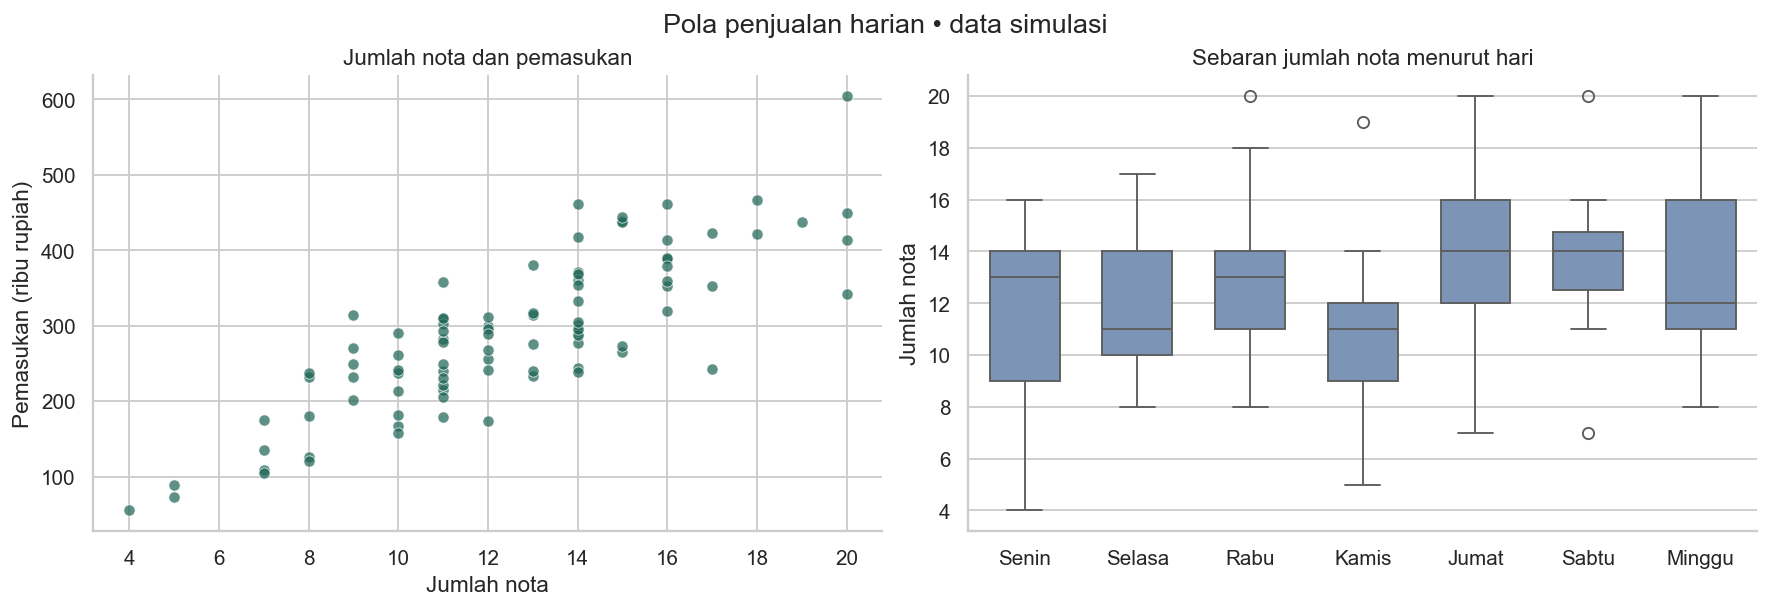

In [5]:
nama_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
penjualan_harian["hari"] = penjualan_harian["tanggal"].dt.dayofweek.map(dict(enumerate(nama_hari)))
penjualan_harian["Pemasukan (ribu rupiah)"] = penjualan_harian["pemasukan"] / 1_000
korelasi = penjualan_harian[["jumlah_nota", "pemasukan"]].rank().corr().loc[
    "jumlah_nota", "pemasukan",
]
per_hari_pekan = penjualan_harian.groupby("hari")["jumlah_nota"].agg(
    Tanggal="size", Median_nota="median",
).reindex(nama_hari)
display(per_hari_pekan.rename_axis("Hari").rename(columns={"Median_nota": "Median nota"}).style
        .format(format_angka))
print(f"Korelasi Spearman jumlah nota dan pemasukan harian sebesar {format_angka(korelasi)}.")

fig, (ax_hubungan, ax_hari) = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
sns.scatterplot(
    data=penjualan_harian, x="jumlah_nota", y="Pemasukan (ribu rupiah)",
    alpha=0.72, color="#206658", ax=ax_hubungan,
)
ax_hubungan.set(xlabel="Jumlah nota", title="Jumlah nota dan pemasukan")
ax_hubungan.xaxis.set_major_locator(MaxNLocator(integer=True))
sns.boxplot(
    data=penjualan_harian, x="hari", y="jumlah_nota", order=nama_hari,
    color="#7392BE", width=0.62, ax=ax_hari,
)
ax_hari.set(xlabel="", ylabel="Jumlah nota", title="Sebaran jumlah nota menurut hari")
ax_hari.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("Pola penjualan harian • data simulasi")
sns.despine(fig=fig)
plt.show()

Jumlah nota dan pemasukan harian cenderung naik bersama. Korelasi Spearman sebesar 0,80 pada 92 tanggal. Hubungan ini wajar karena pemasukan harian dijumlahkan dari nota. Titik-titik dengan jumlah nota sama tetap memiliki pemasukan yang berbeda, sesuai variasi nilai pesanannya.

Jumat dan Sabtu sama-sama memiliki median tertinggi, yaitu 14 nota. Tiap hari dalam sepekan hanya terwakili oleh 13 atau 14 tanggal simulasi. Sebaran antarhari juga saling bertumpuk. Lingkaran di luar kotak menandai nilai di luar batas IQR untuk hari yang sama dalam sepekan. Saat semua tanggal dinilai bersama, jumlah nota masih berada dalam batas IQR global. Jadwal persiapan warung perlu ditinjau dari catatan nyata yang sudah mencakup hari buka, hari tutup, dan kejadian seperti promo atau menu habis.

## 5. Kesimpulan eksplorasi

Kedua CSV punya tanggal yang bisa dipasangkan untuk rekap bulanan. Pemasukan perlu dihitung dari detail menu atau dari total yang diambil sekali per nota, sedangkan jumlah transaksi memakai ID nota yang unik. Empat keterangan pengeluaran yang belum terisi dan nominal yang melampaui IQR tetap dicatat karena nominalnya tersedia. Peninjauan kelompok menunjukkan bahwa ukuran pesanan dan jenis belanja membantu menjelaskan nilai yang tinggi dalam data simulasi.

Notebook 05 memakai data yang sama untuk menjawab lima pertanyaan bisnis. [Analisis dan Rekomendasi untuk Warung](05_analisis_dan_rekomendasi.ipynb).